In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from tensorflow.keras import Model, Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import MeanSquaredLogarithmicError

In [2]:
!pip install -U scikit-learn

  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl (36.7 MB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ ----------------


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
#Step 2: Load the dataset

data = pd.read_csv(
    "http://storage.googleapis.com/download.tensorflow.org/data/ecg.csv",
    header=None
)

print(data.head())
print("Dataset Shape:", data.shape)

        0         1         2         3         4         5         6    \
0 -0.112522 -2.827204 -3.773897 -4.349751 -4.376041 -3.474986 -2.181408   
1 -1.100878 -3.996840 -4.285843 -4.506579 -4.022377 -3.234368 -1.566126   
2 -0.567088 -2.593450 -3.874230 -4.584095 -4.187449 -3.151462 -1.742940   
3  0.490473 -1.914407 -3.616364 -4.318823 -4.268016 -3.881110 -2.993280   
4  0.800232 -0.874252 -2.384761 -3.973292 -4.338224 -3.802422 -2.534510   

        7         8         9    ...       131       132       133       134  \
0 -1.818286 -1.250522 -0.477492  ...  0.792168  0.933541  0.796958  0.578621   
1 -0.992258 -0.754680  0.042321  ...  0.538356  0.656881  0.787490  0.724046   
2 -1.490659 -1.183580 -0.394229  ...  0.886073  0.531452  0.311377 -0.021919   
3 -1.671131 -1.333884 -0.965629  ...  0.350816  0.499111  0.600345  0.842069   
4 -1.783423 -1.594450 -0.753199  ...  1.148884  0.958434  1.059025  1.371682   

        135       136       137       138       139  140  
0  0.2577

In [7]:
#Step 3: Separate features and target
features = data.iloc[:, :-1]
target = data.iloc[:, -1]

print("Features Shape:", features.shape)
print("Target Shape:", target.shape)

# Explanation:

# iloc[:, :-1] selects every row and every column except the last one.

# iloc[:, -1] selects the last column.

Features Shape: (4998, 140)
Target Shape: (4998,)


In [8]:
#Step 4: Split the dataset
x_train, x_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.2,
    stratify=target,
    random_state=42
)

print("Training Shape:", x_train.shape)
print("Testing Shape:", x_test.shape)

Training Shape: (3998, 140)
Testing Shape: (1000, 140)


In [9]:
#Step 5: Select only normal ECG recordings
x_train = x_train[y_train == 1]

print("Normal Training Data:", x_train.shape)

# This is the most important step for novelty detection.
# We train the Autoencoder only on normal ECG recordings.
# However, we retain both classes in the testing dataset.

Normal Training Data: (2335, 140)


In [10]:
# Step 6: Normalize the data
scaler = MinMaxScaler()

x_train_scaled = scaler.fit_transform(x_train)

x_test_scaled = scaler.transform(x_test)

# We scale all features between 0 and 1.
# Notice that we use fit_transform() on training data and only transform() on testing data.

In [11]:
# Step 7: Create the Autoencoder model
# We create a custom Autoencoder by extending the Keras Model class.
class AutoEncoder(Model):

    def __init__(self, output_units):

        super(AutoEncoder, self).__init__()

        self.encoder = Sequential([
            Dense(64, activation='relu'),
            Dense(32, activation='relu'),
            Dense(16, activation='relu'),
            Dense(8, activation='relu')
        ])

        self.decoder = Sequential([
            Dense(16, activation='relu'),
            Dense(32, activation='relu'),
            Dense(64, activation='relu'),
            Dense(output_units, activation='sigmoid')
        ])

    def call(self, inputs):

        encoded = self.encoder(inputs)

        decoded = self.decoder(encoded)

        return decoded

# Why use Sequential?
# Sequential allows us to stack neural network layers in a linear sequence.

# Why Dense(64)?
# It creates 64 neurons in the first encoder layer.

# Why use ReLU?
# It introduces non-linearity into the network.

# Why use sigmoid in the final layer?
# Our input is scaled between 0 and 1.
# Sigmoid produces outputs between 0 and 1, making it suitable for reconstructing these scaled values.

# What is call()?
# The call() method defines the forward pass of the model.
# It specifies how input travels through the encoder and decoder.

In [12]:
# Step 8: Create and compile the model
model = AutoEncoder(output_units=x_train_scaled.shape[1])

model.compile(
    optimizer=Adam(),
    loss=MeanSquaredLogarithmicError(),
    metrics=['mse']
)

# Explanation:
# - optimizer=Adam() updates model weights.
# - loss=MSLE calculates reconstruction loss.
# - metrics=['mse'] monitors Mean Squared Error.
#

In [13]:
#training the model

history = model.fit(
    x_train_scaled,
    x_train_scaled,
    epochs=20,
    batch_size=512,
    validation_split=0.1,
    shuffle=True
)

# Unlike ordinary supervised classification, an Autoencoder uses its input as its expected output.

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 252ms/step - loss: 0.0109 - mse: 0.0247 - val_loss: 0.0109 - val_mse: 0.0244
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - loss: 0.0105 - mse: 0.0237 - val_loss: 0.0103 - val_mse: 0.0231
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - loss: 0.0097 - mse: 0.0219 - val_loss: 0.0094 - val_mse: 0.0211
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - loss: 0.0086 - mse: 0.0195 - val_loss: 0.0084 - val_mse: 0.0189
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - loss: 0.0074 - mse: 0.0169 - val_loss: 0.0074 - val_mse: 0.0166
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - loss: 0.0064 - mse: 0.0145 - val_loss: 0.0066 - val_mse: 0.0148
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 0.0056 - mse: 0.0126 - val_loss: 0.0059 - val_mse: 0.0132
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - loss: 0.0050 - mse: 0.0112 - val_loss: 0.0055 - val_mse: 0.0122
Epoch 9/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - loss: 0.0045 - mse: 0.0102 -

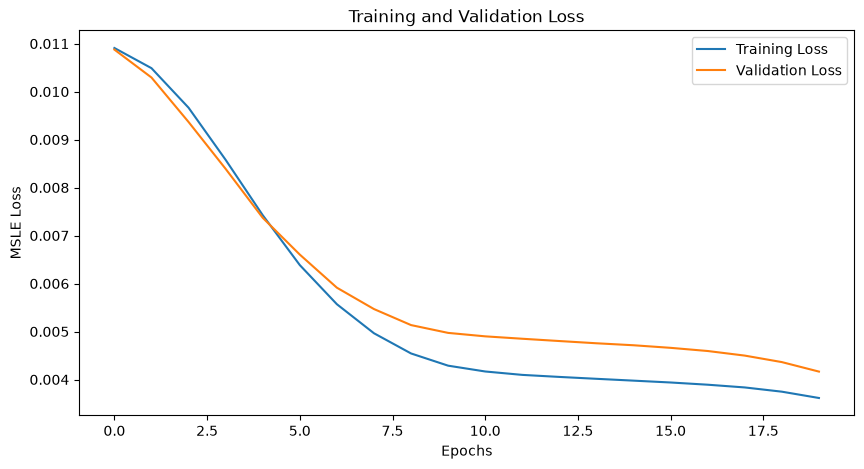

In [14]:
# Step 10: Plot training loss and validation loss
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('MSLE Loss')

plt.title('Training and Validation Loss')

plt.legend()
plt.show()

# How to interpret the graph?
# - Training loss decreasing: Model is learning.
# - Validation loss decreasing: Model is generalizing well to validation data.
# - Training loss decreasing but validation loss increasing: Possible overfitting.

In [15]:
# Step 11: Calculate reconstruction errors
def calculate_reconstruction_errors(model, data):

    reconstructions = model.predict(data, verbose=0)

    errors = np.mean(
        np.square(
            np.log1p(data) - np.log1p(reconstructions)
        ),
        axis=1
    )

    return errors

# Explanation:
# 1. model.predict() reconstructs the input.
# 2. np.log1p() calculates log(1+x).
# 3. We calculate the squared difference.
# 4. np.mean(..., axis=1) calculates the average error for each ECG recording.

In [16]:
# Step 12: Find the anomaly threshold
train_errors = calculate_reconstruction_errors(
    model,
    x_train_scaled
)

threshold = np.mean(train_errors) + np.std(train_errors)

print("Anomaly Threshold:", threshold)

# We calculate the mean and standard deviation of normal training reconstruction errors.
# The threshold determines whether a recording should be considered abnormal.

Anomaly Threshold: 0.008324163577063757


In [17]:
# Step 13: Predict anomalies
test_errors = calculate_reconstruction_errors(
    model,
    x_test_scaled
)

y_pred = (test_errors > threshold).astype(int)

print("Predictions:", y_pred)

# Here:
# - 0 = Normal.
# - 1 = Anomaly.
# If reconstruction error exceeds the threshold, the recording is classified as an anomaly.

Predictions: [1 1 1 0 1 0 1 1 1 0 0 1 1 0 1 0 1 1 0 1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1
 1 0 1 0 0 0 1 0 0 0 1 0 0 1 0 0 0 0 1 0 1 1 1 1 0 0 0 1 1 1 1 0 0 0 1 0 1
 1 1 0 1 0 1 1 0 1 1 0 1 1 0 0 0 1 1 1 1 0 1 0 0 1 1 1 0 0 0 1 1 0 1 0 0 1
 0 0 0 0 1 1 1 0 1 0 1 1 0 1 0 1 1 1 0 1 0 0 0 1 1 1 1 1 1 1 0 0 0 1 0 0 0
 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1 1 0 0 0 1 0 1 0 0 1 0 0 0 1 1 0 1 0 0
 0 1 1 1 1 0 1 0 1 1 0 1 0 0 0 0 0 0 0 1 0 0 1 1 0 0 0 1 1 1 1 1 1 0 0 0 1
 1 0 0 0 1 0 0 1 0 0 0 1 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 1 1 1 1 1 1 1 0 0 1
 0 0 0 1 1 1 1 0 0 0 1 0 1 0 0 1 1 0 1 0 1 0 0 0 0 0 0 0 1 0 1 1 0 0 1 1 1
 0 1 0 1 0 1 0 0 1 0 1 1 0 1 0 0 1 0 0 1 1 0 1 1 1 0 0 1 1 1 0 1 0 1 0 0 0
 0 0 0 0 0 0 1 0 1 1 0 0 1 1 0 1 0 1 0 0 1 1 1 1 0 0 0 1 1 1 0 0 0 1 0 0 0
 0 0 0 0 0 1 0 0 0 1 1 1 0 0 0 1 1 0 1 1 1 1 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1
 1 0 0 0 1 1 0 1 1 1 1 0 1 0 1 1 0 0 0 0 1 1 1 0 0 0 1 0 0 1 0 0 1 0 0 0 0
 1 0 1 0 1 1 0 1 0 1 0 1 0 0 1 0 1 1 1 0 1 1 0 0 1 1 1 0 1 0 1 0 0 1 1 0 0
 0 1 1 0 1 1

C:\Users\SOUMYA JUWATKAR\AppData\Local\Temp\ipykernel_19024\1417873373.py:8: RuntimeWarning: invalid value encountered in log1p
  np.log1p(data) - np.log1p(reconstructions)


In [18]:
# Step 14: Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Accuracy is not sufficient to evaluate anomaly detection.

# We should also examine:
# - Precision.
# - Recall.
# - F1-score.
# - Confusion matrix.
# For medical applications, recall is particularly important because missing an abnormal ECG recording can be serious.


Accuracy: 0.05

Confusion Matrix:
[[  5 411]
 [539  45]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.01      0.01      0.01       416
         1.0       0.10      0.08      0.09       584

    accuracy                           0.05      1000
   macro avg       0.05      0.04      0.05      1000
weighted avg       0.06      0.05      0.05      1000

